# Vibration vs speed and surface: data for the VR vibration formula

Uses the 12 s IMU windows saved by the classification notebook (camera surface label, 200 Hz vertical/horizontal vibration)
and the GPS speed of each window, to find how the real vibration depends on surface and speed:

1. how strong (RMS) the vibration is as a function of speed, per surface: `RMS = K * (v / v_ref) ^ alpha`
2. whether the frequencies move with speed (road bumps fixed in space) or stay fixed (scooter/rider resonance)
3. whether there are regular hits (sidewalk joints) and their spacing in metres
4. (cells 9-13) unusual windows, the wheel (a vibration repeating every C metres), hits, and the full formula,
   tested by making a synthetic signal for every real window and comparing it with the real one

The formula is saved to `vibration_model/vibration_formula.json`; cell 14 writes `vibration_formula_unity.json` for Unity.
Runs on CPU, does not change any classification file.

In [1]:
# 1. Setup: libraries and Google Drive (CPU is enough)

import json
import re
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import welch, find_peaks, butter, sosfiltfilt
from scipy.constants import knot
from IPython.display import display
import ipywidgets as widgets
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# 2. Paths, settings, recordings and hand label fixes (label_fix)

drive_dir = Path("/content/drive/MyDrive")
data_dir = drive_dir / "scooter_data"
win_dir = data_dir / "classification_full"
out_dir = data_dir / "vibration_model"
phone_zip_dirs = [drive_dir, drive_dir / "Data", drive_dir / "gps_datasets"]
out_dir.mkdir(parents = True, exist_ok = True)

fs, win_s = 200, 12
channel_names = ["a_vert", "a_horiz", "g_vert", "g_horiz"]
classes = ["sidewalk", "asphalt"]
colors = {"sidewalk": "tab:orange", "asphalt": "tab:blue"}

v_ref = 4.0
min_speed = 1.0
max_speed_spread = 0.3
min_gps_fixes = 3

recs = {
    "scooter_15min": "scooter_15min_20261008_170556_all_rgb_imu",
    "lab_to_home": "lab_to_home_15min_20261012_184113",
    "gps_outdoor": "gps_outdoor_10min_20261012_172325_gps",
    "field_recording": "field_recording_20261013_171548",
    "field_1014": "field_recording_20261014_165104",
    "field_1016": "field_recording_nogps_20261016_170845",
    "field_1019": "field_recording_nogps_20261019_165722",
    "field_1020": "field_recording_nogps_20261020_170307",
    "field_1021": "field_recording_20261021_171639",
    "field_1026": "field_recording_nogps_20261026_170512",
    "field_1028": "no_gps_color_imu_10min_20261028_170755",
}

label_fix = [
    ("lab_to_home", 442, 454, "sidewalk"),
    ("lab_to_home", 470, 482, "sidewalk"),
]

phone_zips = {
    "field_1016": "University_of_Virginia-2026-10-16_21-09-51.zip",
    "field_1019": "University_of_Virginia-2026-10-19_20-56-30.zip",
    "field_1020": "University_of_Virginia-2026-10-20_21-03-08.zip",
    "field_1021": "University_of_Virginia-2026-10-21_21-13-17.zip",
    "field_1026": "2026-10-26_21-05-13.zip",
    "field_1028": "2026-10-28_21-07-42.zip",
}

def rec_folder(rec):
    if rec in recs and (data_dir / recs[rec]).exists():
        return data_dir / recs[rec]
    m = re.fullmatch(r"field_(\d{4})", rec)
    if m:
        hits = sorted(p for p in data_dir.iterdir() if p.is_dir() and f"2026{m.group(1)}" in p.name)
        if hits:
            return hits[0]
    return None

def phone_zip(rec):
    names = [phone_zips[rec]] if rec in phone_zips else []
    m = re.fullmatch(r"field_(\d{2})(\d{2})", rec)
    for d in phone_zip_dirs:
        for name in names:
            if (d / name).exists():
                return d / name
        if m and d.exists():
            hits = sorted(d.glob(f"*2026-{m.group(1)}-{m.group(2)}_*.zip"))
            if hits:
                return hits[0]
    return None

print("windows from:", win_dir)
print("results to:  ", out_dir)

windows from: /content/drive/MyDrive/scooter_data/classification_full
results to:   /content/drive/MyDrive/scooter_data/vibration_model


In [3]:
# 3. Check camera labels by eye, 12 s at a time (needed for 28 Oct, camera points up); answers go to label_review.csv

review_recs = ["field_1028"]
review_path = out_dir / "label_review.csv"
frames_root = data_dir / "classification" / "frames_all"

review = pd.read_csv(review_path) if review_path.exists() else pd.DataFrame(columns = ["recording", "t_from", "t_to", "label"])
meta_all = pd.read_csv(win_dir / "imu_windows_meta.csv")
blocks = []
for rec in review_recs:
    w = meta_all[meta_all["recording"] == rec]
    starts = sorted({int(t // win_s) * win_s for t in w["t_start"]} | {int((t + win_s - 1e-6) // win_s) * win_s for t in w["t_start"]})
    frames = pd.read_csv(frames_root / f"{rec}_frames.csv")
    for b in starts:
        done = ((review["recording"] == rec) & (review["t_from"] == b)).any()
        cam = w[(w["t_start"] >= b - win_s) & (w["t_start"] < b + win_s)]["label"]
        if not done:
            blocks.append((rec, b, frames[(frames["t"] >= b) & (frames["t"] < b + win_s)]["frame"].tolist(),
                           cam.mode().iloc[0] if len(cam) else "-"))

pos = {"i": 0}
pics = [widgets.Image(format = "jpeg", width = 210) for _ in range(6)]
head = widgets.HTML()

def show_block():
    if pos["i"] >= len(blocks):
        head.value = f"<b>done: {len(review)} blocks answered</b> -> run cell 3 and below"
        for p in pics:
            p.value = b""
        return
    rec, b, frs, cam = blocks[pos["i"]]
    head.value = (f"<b>{pos['i'] + 1} / {len(blocks)}</b> &nbsp; {rec} &nbsp; {b}-{b + win_s} s &nbsp; "
                  f"camera label: {cam} &nbsp; (look at the ground right in front of the scooter)")
    for k, p in enumerate(pics):
        p.value = open(frs[k], "rb").read() if k < len(frs) and Path(frs[k]).exists() else b""

def answer(label):
    global review
    if pos["i"] < len(blocks):
        rec, b, _, _ = blocks[pos["i"]]
        review = review[~((review["recording"] == rec) & (review["t_from"] == b))]
        review = pd.concat([review, pd.DataFrame([{"recording": rec, "t_from": b, "t_to": b + win_s, "label": label}])], ignore_index = True)
        review.to_csv(review_path, index = False)
        pos["i"] += 1
    show_block()

def go_back(_):
    pos["i"] = max(pos["i"] - 1, 0)
    show_block()

btns = [widgets.Button(description = v) for v in ["sidewalk", "asphalt", "mixed"]]
for bt in btns:
    bt.on_click(lambda bt: answer(bt.description))
back = widgets.Button(description = "back")
back.on_click(go_back)
display(widgets.VBox([head, widgets.HBox(pics[:3]), widgets.HBox(pics[3:]), widgets.HBox(btns + [back])]))
show_block()

In [4]:
# 4. Apply the label fixes, then the GPS speed of every window; keep windows with a steady speed above 1 m/s

meta = pd.read_csv(win_dir / "imu_windows_meta.csv")
X = np.load(win_dir / "imu_windows.npz")["X"]
assert len(meta) == len(X), "imu_windows_meta.csv and imu_windows.npz do not match; rerun the window cell"
review_path = out_dir / "label_review.csv"
if review_path.exists():
    review = pd.read_csv(review_path)
    for rec, g in review.groupby("recording"):
        idx = meta.index[meta["recording"] == rec]
        changed = dropped = 0
        for i in idx:
            t0 = meta.at[i, "t_start"]
            over = g[(g["t_from"] < t0 + win_s) & (g["t_to"] > t0)]
            if len(over) == 0:
                continue
            covered = over["t_from"].min() <= t0 and over["t_to"].max() >= t0 + win_s
            labs = set(over["label"])
            if covered and len(labs) == 1 and labs <= set(classes):
                changed += meta.at[i, "label"] != over["label"].iloc[0]
                meta.at[i, "label"] = over["label"].iloc[0]
            else:
                meta.at[i, "label"] = None
                dropped += 1
        print(f"label review: {rec} {len(g)} blocks -> {changed} windows changed, {dropped} not used (mixed / partly checked)")
for rec, t_from, t_to, lab in label_fix:
    sel = (meta["recording"] == rec) & (meta["t_start"] >= t_from) & (meta["t_start"] + win_s <= t_to)
    meta.loc[sel, "label"] = lab
    print(f"label fix: {rec} {t_from}-{t_to} s -> {lab} ({sel.sum()} windows)")

def load_gps(rec):
    folder = rec_folder(rec)
    if folder is None:
        return None, "no folder"
    t0 = pd.read_csv(folder / "accel.csv", usecols = ["bag_time_ns"])["bag_time_ns"].min()
    for name, source in [("gps_parsed.csv", "scooter"), ("gps_phone.csv", "phone")]:
        if (folder / name).exists():
            gps = pd.read_csv(folder / name)
            return pd.DataFrame({"t": (gps["system_time_ns"] - t0) / 1e9,
                                 "speed": gps["speed_knots"] * knot}).dropna(), source
    z = phone_zip(rec)
    if z is not None:
        with zipfile.ZipFile(z) as zf:
            member = [n for n in zf.namelist() if Path(n).name == "Location.csv"]
            if member:
                loc = pd.read_csv(zf.open(member[0]))
                loc = loc[(loc["seconds_elapsed"] >= 0) & (loc["speed"] >= 0)]
                return pd.DataFrame({"t": (loc["time"] - t0) / 1e9, "speed": loc["speed"]}), "phone zip"
    return None, "no GPS"

speed = np.full(len(meta), np.nan)
spread = np.full(len(meta), np.nan)
sources = {}
for rec, idx in meta.groupby("recording").groups.items():
    gps, sources[rec] = load_gps(rec)
    if gps is None:
        continue
    t, s = gps["t"].to_numpy(), gps["speed"].to_numpy()
    for i in idx:
        t0 = meta.at[i, "t_start"]
        sel = s[(t >= t0) & (t < t0 + win_s)]
        if len(sel) >= min_gps_fixes:
            med = np.median(sel)
            speed[i] = med
            spread[i] = (np.percentile(sel, 90) - np.percentile(sel, 10)) / max(med, 1e-6)

meta["speed_mps"] = speed
meta["speed_spread"] = spread
use = (meta["speed_mps"] > min_speed) & (meta["speed_spread"] <= max_speed_spread) & meta["label"].isin(classes)

check = meta.groupby("recording").agg(windows = ("label", "size"), with_speed = ("speed_mps", lambda s: s.notna().sum()))
check["used"] = use.groupby(meta["recording"]).sum()
check["gps"] = [sources.get(r, "") for r in check.index]
display(check)

meta = meta[use].reset_index(drop = True)
X = X[use.to_numpy()]
a_vert = X[:, channel_names.index("a_vert")].astype(float)
a_horiz = X[:, channel_names.index("a_horiz")].astype(float)
print()
for c in classes:
    v = meta.loc[meta["label"] == c, "speed_mps"]
    print(f"{c:9s} windows = {len(v):4d}, recordings = {meta.loc[meta['label'] == c, 'recording'].nunique()}, "
          f"speed {v.min():.1f} .. {v.max():.1f} m/s (median {v.median():.1f})")

label review: field_1028 38 blocks -> 57 windows changed, 27 not used (mixed / partly checked)
label fix: lab_to_home 442-454 s -> sidewalk (1 windows)
label fix: lab_to_home 470-482 s -> sidewalk (1 windows)


,windows,with_speed,used,gps
recording,,,,
field_1014,268,139,84,scooter
field_1016,5,5,4,phone
field_1019,3,3,3,phone
field_1020,5,5,3,phone
field_1021,2,2,1,phone
field_1026,16,16,16,phone zip
field_1028,168,168,66,phone zip
field_recording,115,94,54,scooter
gps_outdoor,145,67,28,scooter



sidewalk  windows =  123, recordings = 8, speed 1.4 .. 6.4 m/s (median 4.5)
asphalt   windows =  205, recordings = 9, speed 3.1 .. 8.1 m/s (median 5.8)


In [5]:
# 5. Vibration numbers per window: RMS, RMS per frequency band, peak frequency, hits

bands = {"0.5-5": (0.5, 5), "5-15": (5, 15), "15-25": (15, 25), "25-40": (25, 40), "40-80": (40, 80)}
f, P = welch(a_vert, fs = fs, nperseg = 2 * fs, axis = 1)
df_f = f[1] - f[0]

feat = meta[["recording", "t_start", "label", "speed_mps"]].copy()
feat["rms_vert"] = np.sqrt(np.mean(a_vert ** 2, axis = 1))
feat["rms_horiz"] = np.sqrt(np.mean(a_horiz ** 2, axis = 1))
for name, (lo, hi) in bands.items():
    sel = (f >= lo) & (f < hi)
    feat[f"rms_{name}"] = np.sqrt(P[:, sel].sum(axis = 1) * df_f)
sel = (f >= 2) & (f <= 60)
feat["peak_hz"] = f[sel][np.argmax(P[:, sel], axis = 1)]

hit_theta = 4 * np.median(feat["rms_vert"])
hit_n, hit_amp = [], []
for x in a_vert:
    pk, prop = find_peaks(np.abs(x), height = hit_theta, distance = int(0.1 * fs))
    hit_n.append(len(pk))
    hit_amp.append(np.median(prop["peak_heights"]) if len(pk) else np.nan)
feat["hits_per_s"] = np.array(hit_n) / win_s
feat["hit_amp"] = hit_amp
feat.to_csv(out_dir / "window_features.csv", index = False)

print(f"hit threshold = {hit_theta:.2f} m/s^2 (4 x median vertical RMS)")
display(feat.groupby("label")[["speed_mps", "rms_vert", "rms_horiz"] + [f"rms_{b}" for b in bands] + ["peak_hz", "hits_per_s"]]
        .median().round(2))

hit threshold = 9.67 m/s^2 (4 x median vertical RMS)


,speed_mps,rms_vert,rms_horiz,rms_0.5-5,rms_5-15,rms_15-25,rms_25-40,rms_40-80,peak_hz,hits_per_s
label,,,,,,,,,,
asphalt,5.80,2.10,3.85,0.47,0.97,1.14,1.14,0.67,18.0,0.17
sidewalk,4.48,2.68,5.23,0.76,1.23,1.60,1.54,1.04,18.5,0.83


,metric,surface,K_at_v_ref,alpha,alpha_5%,alpha_95%,R2,n
0,rms_vert,sidewalk,2.928,0.54,-0.14,0.76,0.20,123
1,rms_vert,asphalt,1.890,0.43,0.13,0.76,0.10,205
2,rms_horiz,sidewalk,5.312,0.65,-0.20,0.88,0.31,123
3,rms_horiz,asphalt,3.800,0.28,0.08,0.59,0.05,205
4,rms_0.5-5,sidewalk,0.759,0.30,-0.59,0.43,0.10,123
5,rms_0.5-5,asphalt,0.537,-0.57,-1.04,-0.15,0.09,205
6,rms_5-15,sidewalk,1.213,0.42,-0.13,0.58,0.18,123
7,rms_5-15,asphalt,0.870,0.38,0.12,0.61,0.07,205
8,rms_15-25,sidewalk,1.684,0.68,-0.15,1.20,0.24,123
9,rms_15-25,asphalt,1.024,0.47,0.09,0.83,0.10,205



leave-one-recording-out error of log(RMS) (smaller is better):
   rms_vert  surface only = 0.401   one alpha = 0.376   alpha per surface = 0.396
   rms_horiz surface only = 0.380   one alpha = 0.370   alpha per surface = 0.378


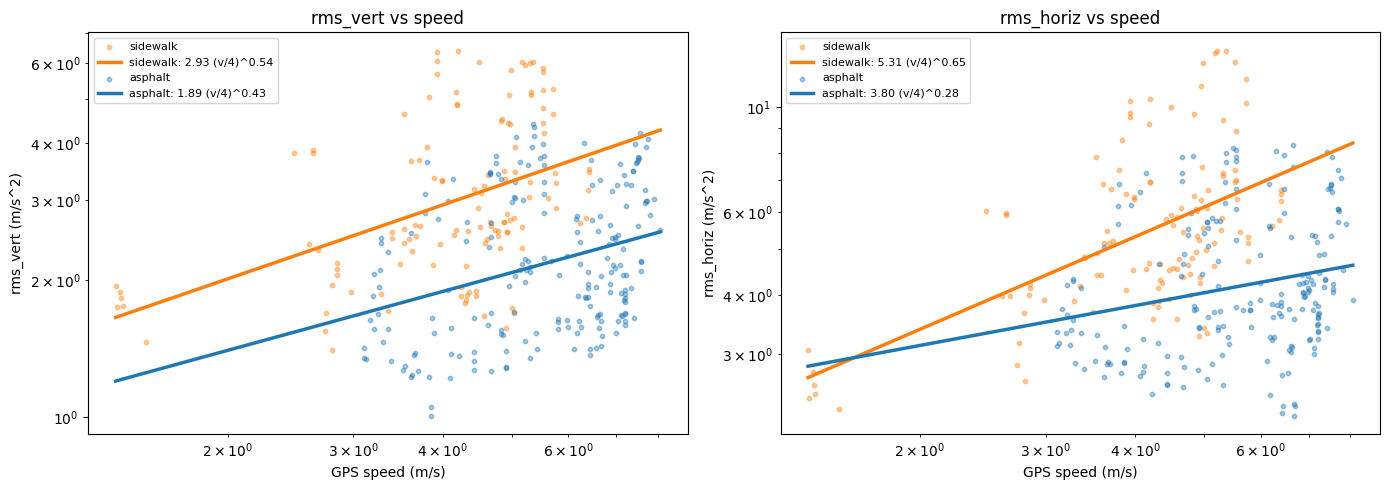

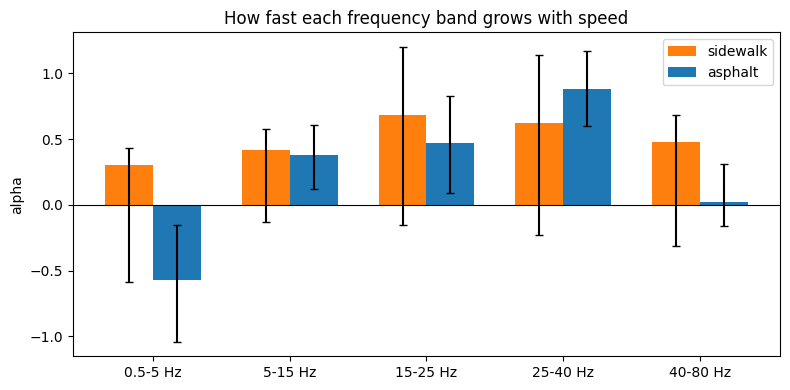

In [6]:
# 6. Vibration strength vs speed: RMS = K * (v / 4) ^ alpha per surface, and which model fits best

def fit_power(v, y):
    A = np.column_stack([np.ones(len(v)), np.log(v / v_ref)])
    coef, *_ = np.linalg.lstsq(A, np.log(y), rcond = None)
    r2 = 1 - np.var(np.log(y) - A @ coef) / np.var(np.log(y))
    return np.exp(coef[0]), coef[1], r2

def design(d, model):
    cols = [(d["label"] == c).astype(float) for c in classes]
    lv = np.log(d["speed_mps"] / v_ref)
    if model == "one alpha":
        cols.append(lv)
    if model == "alpha per surface":
        cols += [lv * (d["label"] == c) for c in classes]
    return np.column_stack(cols)

def loro_error(metric, model):
    err = []
    for rec in feat["recording"].unique():
        tr, te = feat[feat["recording"] != rec], feat[feat["recording"] == rec]
        if te["label"].nunique() == 0 or not set(te["label"]) <= set(tr["label"]):
            continue
        coef, *_ = np.linalg.lstsq(design(tr, model), np.log(tr[metric]), rcond = None)
        err.append(np.log(te[metric]) - design(te, model) @ coef)
    return np.sqrt(np.mean(np.concatenate(err) ** 2))

rng = np.random.default_rng(0)
metrics = ["rms_vert", "rms_horiz"] + [f"rms_{b}" for b in bands]
rows = []
for metric in metrics:
    for c in classes:
        d = feat[feat["label"] == c]
        K, alpha, r2 = fit_power(d["speed_mps"].to_numpy(), d[metric].to_numpy())
        recs_c = d["recording"].unique()
        boot = []
        for _ in range(500):
            pick = rng.choice(recs_c, len(recs_c))
            b = pd.concat([d[d["recording"] == r] for r in pick])
            if b["speed_mps"].max() / b["speed_mps"].min() > 1.3:
                boot.append(fit_power(b["speed_mps"].to_numpy(), b[metric].to_numpy())[1])
        lo, hi = np.percentile(boot, [5, 95]) if boot else (np.nan, np.nan)
        rows.append({"metric": metric, "surface": c, "K_at_v_ref": round(K, 3), "alpha": round(alpha, 2),
                     "alpha_5%": round(lo, 2), "alpha_95%": round(hi, 2), "R2": round(r2, 2), "n": len(d)})
fits = pd.DataFrame(rows)
fits.to_csv(out_dir / "speed_fits.csv", index = False)
display(fits)

print("\nleave-one-recording-out error of log(RMS) (smaller is better):")
for metric in ["rms_vert", "rms_horiz"]:
    errs = {m: loro_error(metric, m) for m in ["surface only", "one alpha", "alpha per surface"]}
    print(f"   {metric:9s} " + "   ".join(f"{m} = {e:.3f}" for m, e in errs.items()))

fig, axes = plt.subplots(1, 2, figsize = (14, 5))
vv = np.linspace(feat["speed_mps"].min(), feat["speed_mps"].max(), 50)
for ax, metric in zip(axes, ["rms_vert", "rms_horiz"]):
    for c in classes:
        d = feat[feat["label"] == c]
        ax.scatter(d["speed_mps"], d[metric], s = 10, alpha = 0.4, color = colors[c], label = c)
        r = fits[(fits["metric"] == metric) & (fits["surface"] == c)].iloc[0]
        ax.plot(vv, r["K_at_v_ref"] * (vv / v_ref) ** r["alpha"], color = colors[c], linewidth = 2.5,
                label = f"{c}: {r['K_at_v_ref']:.2f} (v/{v_ref:g})^{r['alpha']:.2f}")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("GPS speed (m/s)")
    ax.set_ylabel(f"{metric} (m/s^2)")
    ax.set_title(f"{metric} vs speed")
    ax.legend(fontsize = 8)
plt.tight_layout()
plt.savefig(out_dir / "rms_vs_speed.png", dpi = 150)
plt.show()

fig, ax = plt.subplots(figsize = (8, 4))
x = np.arange(len(bands))
for k, c in enumerate(classes):
    r = fits[(fits["surface"] == c) & fits["metric"].isin([f"rms_{b}" for b in bands])]
    ax.bar(x + (k - 0.5) * 0.35, r["alpha"], 0.35, color = colors[c], label = c,
           yerr = [r["alpha"] - r["alpha_5%"], r["alpha_95%"] - r["alpha"]], capsize = 3)
ax.set_xticks(x)
ax.set_xticklabels([f"{b} Hz" for b in bands])
ax.axhline(0, color = "k", linewidth = 0.8)
ax.set_ylabel("alpha")
ax.set_title("How fast each frequency band grows with speed")
ax.legend()
plt.tight_layout()
plt.savefig(out_dir / "alpha_per_band.png", dpi = 150)
plt.show()

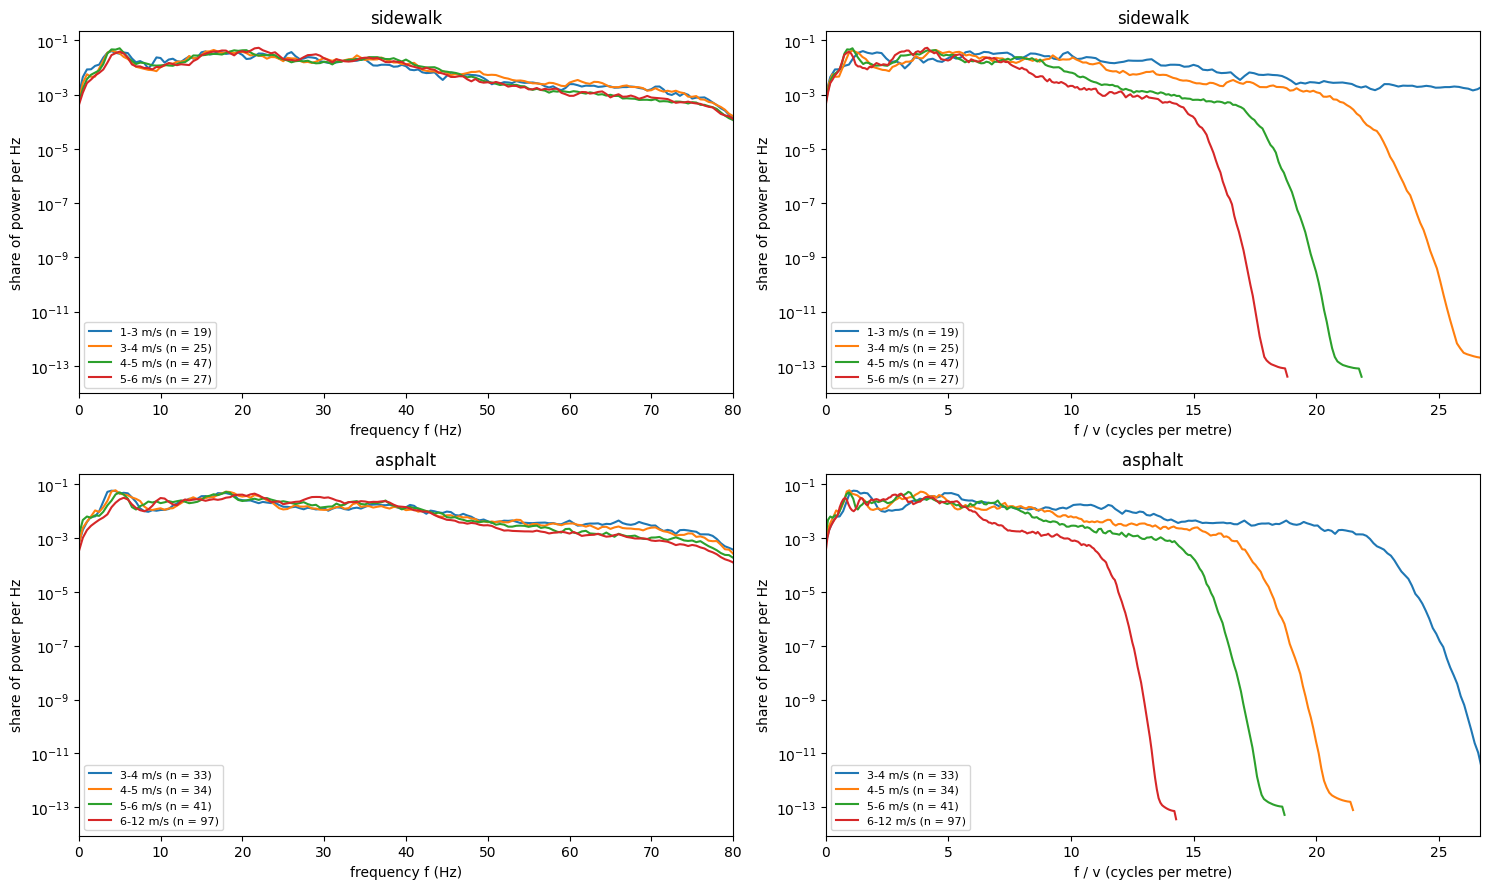

sidewalk  spread vs f = 0.193, vs f / v = 0.515  ->  fixed frequencies (f)
asphalt   spread vs f = 0.236, vs f / v = 0.477  ->  fixed frequencies (f)

peak frequency vs speed (slope in Hz per m/s; 0 = fixed, peak / v = constant if it moves with speed):
   sidewalk  peak = 11.3 + 1.12 * v   (corr = 0.17, median peak = 18.5 Hz)
   asphalt   peak = 0.7 + 2.86 * v   (corr = 0.48, median peak = 18.0 Hz)


In [7]:
# 7. Do the frequencies move with speed? Spectrum in speed groups, against f and against f / v

speed_edges = [1, 3, 4, 5, 6, 12]
min_group = 8
f_grid = np.linspace(2, 60, 200)

shape = P / (P[:, (f >= 0.5) & (f <= 80)].sum(axis = 1, keepdims = True) * df_f)
summary = {}
fig, axes = plt.subplots(2, 2, figsize = (15, 9))
for row, c in enumerate(classes):
    groups = []
    for lo, hi in zip(speed_edges[:-1], speed_edges[1:]):
        sel = ((feat["label"] == c) & (feat["speed_mps"] >= lo) & (feat["speed_mps"] < hi)).to_numpy()
        if sel.sum() >= min_group:
            groups.append((lo, hi, np.median(feat.loc[sel, "speed_mps"]), shape[sel].mean(axis = 0), sel.sum()))
    for lo, hi, v_med, s_mean, n in groups:
        lab = f"{lo}-{hi} m/s (n = {n})"
        axes[row, 0].semilogy(f, s_mean, label = lab)
        axes[row, 1].semilogy(f / v_med, s_mean, label = lab)
    axes[row, 0].set_xlim(0, 80)
    axes[row, 0].set_xlabel("frequency f (Hz)")
    axes[row, 1].set_xlim(0, 80 / speed_edges[1])
    axes[row, 1].set_xlabel("f / v (cycles per metre)")
    for ax in axes[row]:
        ax.set_title(c)
        ax.set_ylabel("share of power per Hz")
        ax.legend(fontsize = 8)

    if len(groups) >= 2:
        curves_f = np.array([np.interp(f_grid, f, np.log(g[3] + 1e-12)) for g in groups])
        n_lo = max(2 / g[2] for g in groups)
        n_hi = min(60 / g[2] for g in groups)
        n_grid = np.linspace(n_lo, n_hi, 200)
        curves_n = np.array([np.interp(n_grid * g[2], f, np.log(g[3] + 1e-12)) for g in groups])
        summary[c] = {"spread_vs_f": float(np.mean(np.std(curves_f, axis = 0))),
                      "spread_vs_f_over_v": float(np.mean(np.std(curves_n, axis = 0)))}
plt.tight_layout()
plt.savefig(out_dir / "spectrum_vs_speed.png", dpi = 150)
plt.show()

for c, s in summary.items():
    better = "fixed frequencies (f)" if s["spread_vs_f"] < s["spread_vs_f_over_v"] else "moves with speed (f / v)"
    print(f"{c:9s} spread vs f = {s['spread_vs_f']:.3f}, vs f / v = {s['spread_vs_f_over_v']:.3f}  ->  {better}")

print("\npeak frequency vs speed (slope in Hz per m/s; 0 = fixed, peak / v = constant if it moves with speed):")
for c in classes:
    d = feat[feat["label"] == c]
    slope, icpt = np.polyfit(d["speed_mps"], d["peak_hz"], 1)
    corr = np.corrcoef(d["speed_mps"], d["peak_hz"])[0, 1]
    print(f"   {c:9s} peak = {icpt:.1f} + {slope:.2f} * v   (corr = {corr:.2f}, median peak = {d['peak_hz'].median():.1f} Hz)")

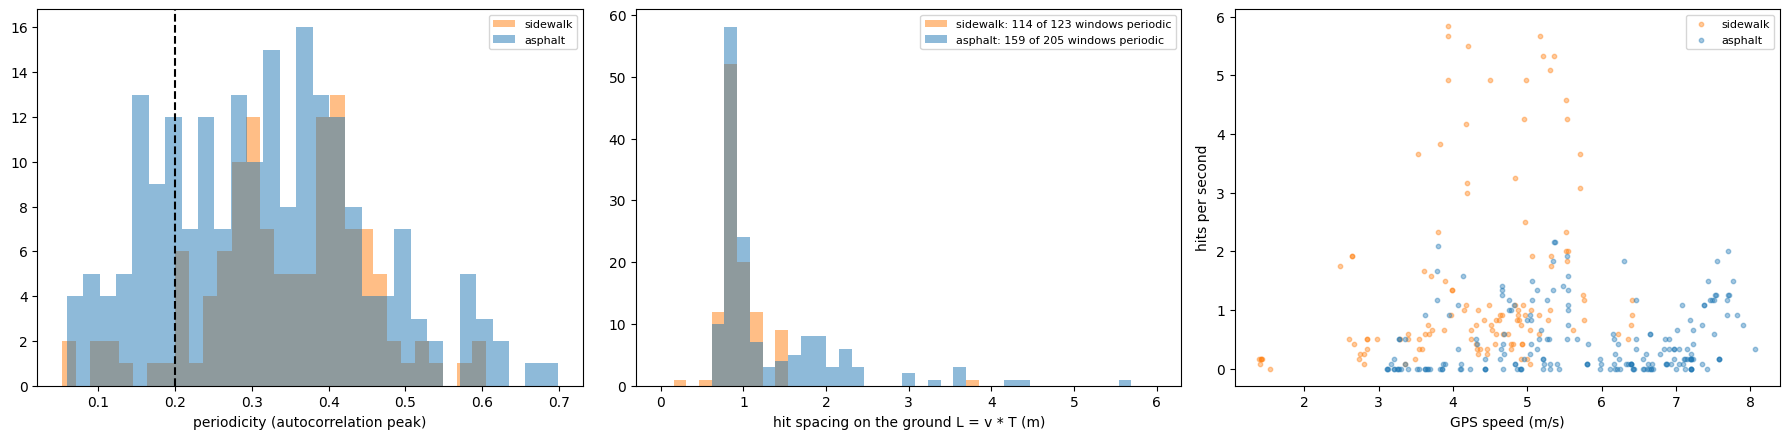

sidewalk  periodic windows = 93%, spacing = 0.90 m (IQR 0.82-1.05), hits per metre = 0.33 (1 hit every 3.01 m), median hit = 13.4 m/s^2
asphalt   periodic windows = 78%, spacing = 0.97 m (IQR 0.86-1.84), hits per metre = 0.08 (1 hit every 12.73 m), median hit = 12.4 m/s^2


In [8]:
# 8. Regular hits: period of the hits and their spacing on the ground

def hit_period(x, lag_min = 0.15, lag_max = 2.0):
    env = sosfiltfilt(butter(2, 10, "low", fs = fs, output = "sos"), np.abs(x))
    env = env - env.mean()
    ac = np.correlate(env, env, mode = "full")[len(env) - 1:]
    ac = ac / ac[0]
    lags = np.arange(int(lag_min * fs), int(lag_max * fs))
    pk, prop = find_peaks(ac[lags], height = 0)
    if len(pk) == 0:
        return np.nan, 0.0
    h = prop["peak_heights"]
    best = pk[np.argmax(h >= 0.8 * h.max())]
    return lags[best] / fs, h.max()

res = np.array([hit_period(x) for x in a_vert])
feat["hit_period_s"], feat["periodicity"] = res[:, 0], res[:, 1]
feat["spacing_m"] = feat["speed_mps"] * feat["hit_period_s"]
min_periodicity = 0.2
periodic = feat["periodicity"] >= min_periodicity

fig, axes = plt.subplots(1, 3, figsize = (18, 4.5))
for c in classes:
    d = feat[feat["label"] == c]
    dp = d[periodic[d.index]]
    axes[0].hist(d["periodicity"], bins = 30, alpha = 0.5, color = colors[c], label = c)
    axes[1].hist(dp["spacing_m"], bins = np.linspace(0, 6, 40), alpha = 0.5, color = colors[c],
                 label = f"{c}: {len(dp)} of {len(d)} windows periodic")
    axes[2].scatter(d["speed_mps"], d["hits_per_s"], s = 10, alpha = 0.4, color = colors[c], label = c)
axes[0].axvline(min_periodicity, color = "k", linestyle = "--")
axes[0].set_xlabel("periodicity (autocorrelation peak)")
axes[1].set_xlabel("hit spacing on the ground L = v * T (m)")
axes[2].set_xlabel("GPS speed (m/s)")
axes[2].set_ylabel("hits per second")
for ax in axes:
    ax.legend(fontsize = 8)
plt.tight_layout()
plt.savefig(out_dir / "hits_and_spacing.png", dpi = 150)
plt.show()

joints = {}
for c in classes:
    d = feat[feat["label"] == c]
    dp = d[periodic[d.index]]
    v, h = d["speed_mps"].to_numpy(), d["hits_per_s"].to_numpy()
    per_m = (v @ h) / (v @ v)
    joints[c] = {"periodic_share": float(len(dp) / len(d)),
                 "spacing_m": float(dp["spacing_m"].median()) if len(dp) else None,
                 "spacing_iqr_m": [float(x) for x in dp["spacing_m"].quantile([0.25, 0.75])] if len(dp) else None,
                 "hits_per_m": float(per_m),
                 "hit_amp_mps2": float(d["hit_amp"].median()) if d["hit_amp"].notna().any() else None}
    sp = "none" if not len(dp) else f"{joints[c]['spacing_m']:.2f} m (IQR {joints[c]['spacing_iqr_m'][0]:.2f}-{joints[c]['spacing_iqr_m'][1]:.2f})"
    print(f"{c:9s} periodic windows = {joints[c]['periodic_share']:.0%}, spacing = {sp}, "
          f"hits per metre = {per_m:.2f} (1 hit every {1 / per_m if per_m > 0 else np.inf:.2f} m), "
          f"median hit = {joints[c]['hit_amp_mps2'] or float('nan'):.1f} m/s^2")

In [9]:
# 9. Save the per-surface numbers (vibration_model_params.json)

params = {"v_ref_mps": v_ref, "fs_hz": fs, "bands_hz": bands, "hit_threshold_mps2": float(hit_theta), "surfaces": {}}
for c in classes:
    d = feat[feat["label"] == c]
    fc = fits[fits["surface"] == c].set_index("metric")
    params["surfaces"][c] = {
        "n_windows": int(len(d)),
        "recordings": sorted(d["recording"].unique().tolist()),
        "speed_range_mps": [float(d["speed_mps"].quantile(0.05)), float(d["speed_mps"].quantile(0.95))],
        "rms": {m: {"K": float(fc.at[m, "K_at_v_ref"]), "alpha": float(fc.at[m, "alpha"]),
                    "alpha_90ci": [float(fc.at[m, "alpha_5%"]), float(fc.at[m, "alpha_95%"])], "R2": float(fc.at[m, "R2"])}
                for m in metrics},
        "spectrum": summary.get(c, {}),
        "median_peak_hz": float(d["peak_hz"].median()),
        "joints": joints[c],
    }
    sel = (feat["label"] == c).to_numpy() & (np.abs(feat["speed_mps"] - v_ref) < 1.0).to_numpy()
    if sel.sum() >= min_group:
        params["surfaces"][c]["psd_shape_at_v_ref"] = {"f_hz": f[f <= 80].tolist(), "share_per_hz": shape[sel][:, f <= 80].mean(axis = 0).tolist()}

with open(out_dir / "vibration_model_params.json", "w") as fh:
    json.dump(params, fh, indent = 1)

print("saved", out_dir / "vibration_model_params.json")
for c, p in params["surfaces"].items():
    r = p["rms"]["rms_vert"]
    print(f"\n{c}: {p['n_windows']} windows from {len(p['recordings'])} recordings, "
          f"speed {p['speed_range_mps'][0]:.1f}-{p['speed_range_mps'][1]:.1f} m/s")
    print(f"   vertical RMS = {r['K']:.2f} * (v / {v_ref:g}) ^ {r['alpha']:.2f}   (alpha 90% range {r['alpha_90ci'][0]:.2f}..{r['alpha_90ci'][1]:.2f}, R2 = {r['R2']:.2f})")
    for b in bands:
        rb = p["rms"][f"rms_{b}"]
        print(f"   {b:>6s} Hz: {rb['K']:.2f} * (v / {v_ref:g}) ^ {rb['alpha']:.2f}")
    j = p["joints"]
    print(f"   joints: {j['periodic_share']:.0%} periodic windows, spacing {j['spacing_m']}, {j['hits_per_m']:.2f} hits per metre")

saved /content/drive/MyDrive/scooter_data/vibration_model/vibration_model_params.json

sidewalk: 123 windows from 8 recordings, speed 2.5-5.8 m/s
   vertical RMS = 2.93 * (v / 4) ^ 0.54   (alpha 90% range -0.14..0.76, R2 = 0.20)
    0.5-5 Hz: 0.76 * (v / 4) ^ 0.30
     5-15 Hz: 1.21 * (v / 4) ^ 0.42
    15-25 Hz: 1.68 * (v / 4) ^ 0.68
    25-40 Hz: 1.54 * (v / 4) ^ 0.62
    40-80 Hz: 0.99 * (v / 4) ^ 0.48
   joints: 93% periodic windows, spacing 0.8983646411334522, 0.33 hits per metre

asphalt: 205 windows from 9 recordings, speed 3.3-7.6 m/s
   vertical RMS = 1.89 * (v / 4) ^ 0.43   (alpha 90% range 0.13..0.76, R2 = 0.10)
    0.5-5 Hz: 0.54 * (v / 4) ^ -0.57
     5-15 Hz: 0.87 * (v / 4) ^ 0.38
    15-25 Hz: 1.02 * (v / 4) ^ 0.47
    25-40 Hz: 0.84 * (v / 4) ^ 0.88
    40-80 Hz: 0.72 * (v / 4) ^ 0.02
   joints: 78% periodic windows, spacing 0.9699809377675712, 0.08 hits per metre


5 of 328 windows are above 2x the fit


,recording,label,t_from,t_to,windows,speed,rms_vert,x_fit,hits_per_s
stretch,,,,,,,,,
1,field_1014,asphalt,838.0,850.0,1,5.37,4.35,2.03,2.17
2,field_1019,asphalt,556.0,568.0,1,5.35,4.41,2.06,1.33
3,field_1028,sidewalk,306.0,322.0,3,3.93,6.35,2.13,5.67


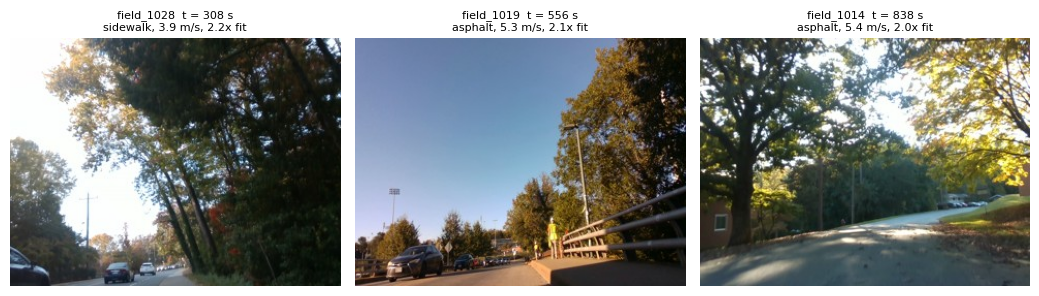

In [10]:
# 10. Unusual windows (more than 2x the fit) with their camera frame, to find wrong labels

frames_root = data_dir / "classification" / "frames_all"
odd_factor = 2.0

fit_of = fits[fits["metric"] == "rms_vert"].set_index("surface")
K_of = fit_of.loc[feat["label"], "K_at_v_ref"].to_numpy()
a_of = fit_of.loc[feat["label"], "alpha"].to_numpy()
feat["ratio_to_fit"] = feat["rms_vert"] / (K_of * (feat["speed_mps"] / v_ref) ** a_of)
odd = feat[feat["ratio_to_fit"] > odd_factor].sort_values(["recording", "t_start"])
print(f"{len(odd)} of {len(feat)} windows are above {odd_factor:g}x the fit")

if len(odd):
    new_stretch = (odd["recording"] != odd["recording"].shift()) | (odd["t_start"].diff() > win_s)
    odd = odd.assign(stretch = new_stretch.cumsum())
    display(odd.groupby("stretch").agg(recording = ("recording", "first"), label = ("label", "first"),
                                       t_from = ("t_start", "min"), t_to = ("t_start", lambda s: s.max() + win_s),
                                       windows = ("t_start", "size"), speed = ("speed_mps", "median"),
                                       rms_vert = ("rms_vert", "median"), x_fit = ("ratio_to_fit", "median"),
                                       hits_per_s = ("hits_per_s", "median")).round(2))
    worst = odd.sort_values("ratio_to_fit", ascending = False).drop_duplicates("stretch").head(6)
    fig, axes = plt.subplots(1, len(worst), figsize = (3.5 * len(worst), 3.3), squeeze = False)
    for ax, (_, w) in zip(axes[0], worst.iterrows()):
        ax.axis("off")
        csv = frames_root / f"{w['recording']}_frames.csv"
        if csv.exists():
            fr = pd.read_csv(csv)
            fr = fr[(fr["t"] >= w["t_start"]) & (fr["t"] < w["t_start"] + win_s)]
            if len(fr) and Path(fr["frame"].iloc[len(fr) // 2]).exists():
                ax.imshow(plt.imread(fr["frame"].iloc[len(fr) // 2]))
        ax.set_title(f"{w['recording']}  t = {w['t_start']:.0f} s\n{w['label']}, {w['speed_mps']:.1f} m/s, "
                     f"{w['ratio_to_fit']:.1f}x fit", fontsize = 8)
    plt.tight_layout()
    plt.savefig(out_dir / "unusual_windows.png", dpi = 150)
    plt.show()

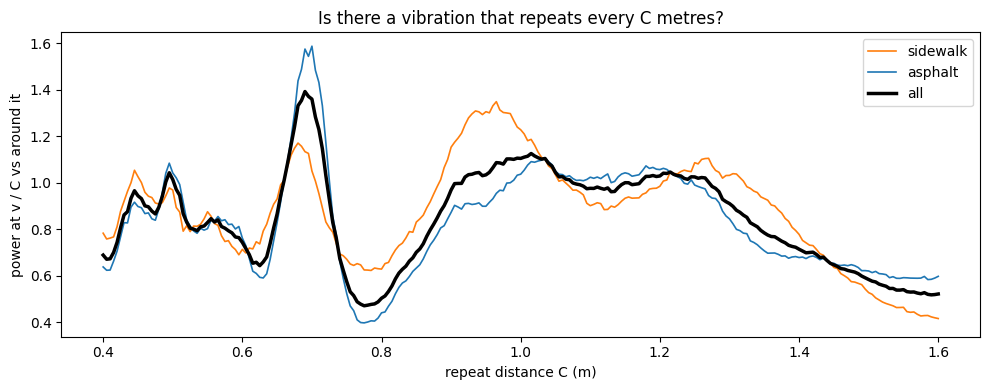

sidewalk  best C = 0.965 m, power ratio there = 1.35 (typical 0.91)
asphalt   best C = 0.700 m, power ratio there = 1.59 (typical 0.83)
all       best C = 0.690 m, power ratio there = 1.39 (typical 0.86)
-> clear repeat at C = 0.690 m (wheel diameter would be 22.0 cm)
   sidewalk  wheel sine amplitude = 0.207 * (v / 4) ^ 0.28  (R2 = 0.01, 73 windows)
   asphalt   wheel sine amplitude = 0.206 * (v / 4) ^ 0.49  (R2 = 0.04, 137 windows)


In [11]:
# 11. Wheel: vibration that repeats every C metres (one wheel turn)

C_grid = np.arange(0.4, 1.6, 0.005)
fw, Pw = welch(a_vert, fs = fs, nperseg = 8 * fs, axis = 1)
dfw = fw[1] - fw[0]

def line_power(P_row, f0, half = 0.2, side = (0.5, 1.2)):
    on = np.abs(fw - f0) <= half
    off = (np.abs(fw - f0) > side[0]) & (np.abs(fw - f0) <= side[1])
    base = P_row[off].mean()
    return P_row[on].mean() / base, max(P_row[on].sum() - base * on.sum(), 0) * dfw

v_all = feat["speed_mps"].to_numpy()
log_ratio = np.array([[np.log(line_power(Pw[i], v_all[i] / C)[0]) for C in C_grid] for i in range(len(feat))])

fig, ax = plt.subplots(figsize = (10, 4))
wheel = {}
for c in classes + ["all"]:
    sel = np.ones(len(feat), bool) if c == "all" else (feat["label"] == c).to_numpy()
    score = log_ratio[sel].mean(axis = 0)
    ax.plot(C_grid, np.exp(score), label = c, color = colors.get(c, "k"), linewidth = 2.5 if c == "all" else 1.2)
    wheel[c] = {"C_m": float(C_grid[np.argmax(score)]), "peak_ratio": float(np.exp(score.max())),
                "typical_ratio": float(np.exp(np.median(score)))}
ax.set_xlabel("repeat distance C (m)")
ax.set_ylabel("power at v / C vs around it")
ax.set_title("Is there a vibration that repeats every C metres?")
ax.legend()
plt.tight_layout()
plt.savefig(out_dir / "wheel_repeat_distance.png", dpi = 150)
plt.show()

C_wheel = wheel["all"]["C_m"]
clear_wheel = wheel["all"]["peak_ratio"] >= 1.5 * wheel["all"]["typical_ratio"]
for c, w in wheel.items():
    print(f"{c:9s} best C = {w['C_m']:.3f} m, power ratio there = {w['peak_ratio']:.2f} (typical {w['typical_ratio']:.2f})")
print(f"-> {'clear' if clear_wheel else 'NO clear'} repeat at C = {C_wheel:.3f} m "
      f"(wheel diameter would be {C_wheel / np.pi * 100:.1f} cm)")

feat["wheel_amp"] = [np.sqrt(2 * line_power(Pw[i], v_all[i] / C_wheel)[1]) for i in range(len(feat))]
wheel_fit = {}
for c in classes:
    d = feat[(feat["label"] == c) & (feat["wheel_amp"] > 0)]
    K_w, alpha_w, r2_w = fit_power(d["speed_mps"].to_numpy(), d["wheel_amp"].to_numpy()) if len(d) > 5 else (0.0, 0.0, 0.0)
    wheel_fit[c] = {"K": float(K_w if clear_wheel else 0.0), "alpha": float(alpha_w), "R2": float(r2_w)}
    print(f"   {c:9s} wheel sine amplitude = {K_w:.3f} * (v / {v_ref:g}) ^ {alpha_w:.2f}  (R2 = {r2_w:.2f}, "
          f"{len(d)} windows){'' if clear_wheel else '   -> not used, no clear wheel line'}")

sidewalk  base RMS = 2.12 * (v / 4) ^ 0.54 (R2 = 0.41), hits: 2060, 0.33 per metre, median size 13.9 m/s^2
asphalt   base RMS = 1.67 * (v / 4) ^ 0.32 (R2 = 0.11), hits: 1104, 0.08 per metre, median size 12.4 m/s^2


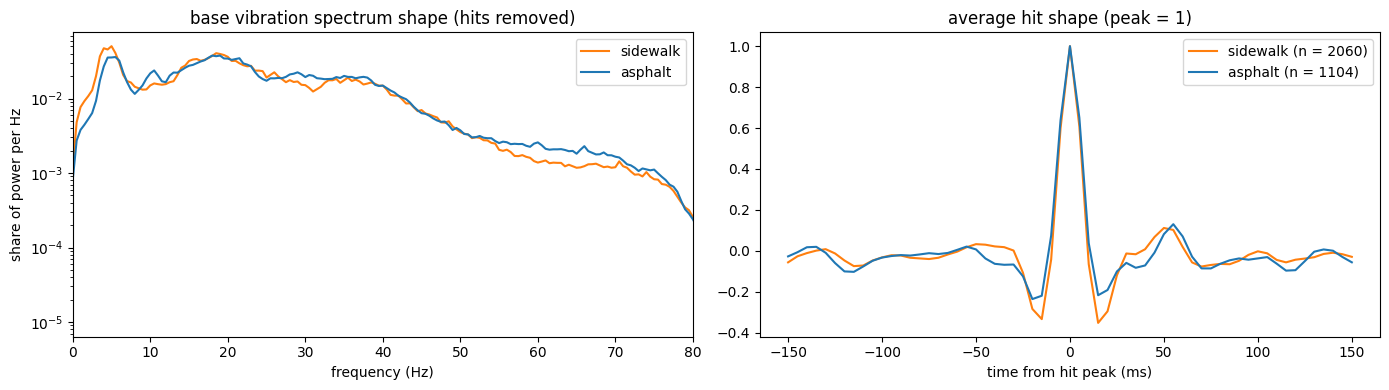

In [12]:
# 12. Hits and base vibration: hit shape, base RMS vs speed, base spectrum shape

half_hit = int(0.15 * fs)
cut = int(0.1 * fs)
base_rms, base_P, templates, amps = [], [], {c: [] for c in classes}, {c: [] for c in classes}
for x, lab in zip(a_vert, feat["label"]):
    pk, prop = find_peaks(np.abs(x), height = hit_theta, distance = int(0.1 * fs))
    keep = np.ones(len(x), bool)
    for p in pk:
        keep[max(p - cut, 0):p + cut] = False
        if half_hit <= p < len(x) - half_hit:
            seg = x[p - half_hit:p + half_hit + 1]
            templates[lab].append(seg * np.sign(x[p]) / np.abs(x[p]))
            amps[lab].append(np.abs(x[p]))
    xb = np.where(keep, x, 0.0)
    base_rms.append(np.sqrt(np.sum(xb ** 2) / keep.sum()))
    _, Pb = welch(xb, fs = fs, nperseg = 2 * fs)
    base_P.append(Pb * len(x) / keep.sum())
base_P = np.array(base_P)
feat["rms_base"] = np.sqrt(np.maximum(np.array(base_rms) ** 2 - feat["wheel_amp"].fillna(0) ** 2 / 2 * clear_wheel, 1e-6))

model = {}
fig, axes = plt.subplots(1, 2, figsize = (14, 4))
for c in classes:
    sel = (feat["label"] == c).to_numpy()
    K_b, alpha_b, r2_b = fit_power(feat.loc[sel, "speed_mps"].to_numpy(), feat.loc[sel, "rms_base"].to_numpy())
    shp = base_P[sel] / (base_P[sel][:, (f >= 0.5) & (f <= 80)].sum(axis = 1, keepdims = True) * df_f)
    shp = shp.mean(axis = 0)
    tmpl = np.mean(templates[c], axis = 0) if templates[c] else np.zeros(2 * half_hit + 1)
    tmpl = tmpl / max(np.abs(tmpl).max(), 1e-9)
    model[c] = {"K_base": K_b, "alpha_base": alpha_b, "R2_base": r2_b, "shape_f": f, "shape": shp,
                "hits_per_m": joints[c]["hits_per_m"], "hit_amps": np.array(amps[c]), "template": tmpl,
                "wheel_K": wheel_fit[c]["K"], "wheel_alpha": wheel_fit[c]["alpha"]}
    print(f"{c:9s} base RMS = {K_b:.2f} * (v / {v_ref:g}) ^ {alpha_b:.2f} (R2 = {r2_b:.2f}), hits: {len(amps[c])}, "
          f"{joints[c]['hits_per_m']:.2f} per metre, median size {np.median(amps[c]) if amps[c] else 0:.1f} m/s^2")
    axes[0].semilogy(f, shp, color = colors[c], label = c)
    axes[1].plot(np.arange(-half_hit, half_hit + 1) / fs * 1000, tmpl, color = colors[c], label = f"{c} (n = {len(amps[c])})")
axes[0].set_xlim(0, 80)
axes[0].set_xlabel("frequency (Hz)")
axes[0].set_ylabel("share of power per Hz")
axes[0].set_title("base vibration spectrum shape (hits removed)")
axes[1].set_xlabel("time from hit peak (ms)")
axes[1].set_title("average hit shape (peak = 1)")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.savefig(out_dir / "base_shape_and_hit.png", dpi = 150)
plt.show()

rms_vert       rms_0.5-5       rms_5-15       rms_15-25  \
source                formula  real   formula  real  formula  real   formula   
label    speed_group                                                           
asphalt  (3, 4]          1.77  1.56      0.42  0.47     0.82  0.72      1.01   
         (4, 5]          2.03  1.80      0.46  0.58     0.95  0.95      1.17   
         (5, 6]          2.05  2.22      0.48  0.63     0.96  1.22      1.16   
         (6, 12]         2.31  2.17      0.53  0.33     1.07  0.97      1.33   
sidewalk (1, 3]          2.19  1.94      0.58  0.58     0.87  0.90      1.37   
         (3, 4]          2.75  2.63      0.69  0.78     1.05  1.21      1.70   
         (4, 5]          3.13  2.63      0.80  0.84     1.21  1.26      1.90   
         (5, 6]          3.36  4.22      0.85  0.94     1.34  1.67      2.08   
         (6, 12]         3.51  3.16      0.90  0.61     1.40  1.29      2.13   

                           rms_25-40       rms_40-80       hits_per_s        
source                real   formula  real   formula  real    formula  real  
label    speed_group                                                         
asphalt  (3, 4]       0.71      0.94  0.71      0.61  0.67       0.25  0.00  
         (4, 5]       0.93      1.09  0.84      0.68  0.60       0.33  0.21  
         (5, 6]       1.28      1.09  1.26      0.71  0.88       0.33  0.50  
         (6, 12]      1.20      1.23  1.24      0.78  0.67       0.42  0.17  
sidewalk (1, 3]       1.00      1.23  0.86      0.70  0.70       0.58  0.25  
         (3, 4]       1.60      1.59  1.49      0.85  1.13       1.00  0.75  
         (4, 5]       1.41      1.78  1.28      0.95  0.99       1.25  0.83  
         (5, 6]       2.49      1.90  2.25      1.05  1.26       1.33  1.83  
         (6, 12]      2.07      1.98  1.74      1.09  1.00       1.58  0.75

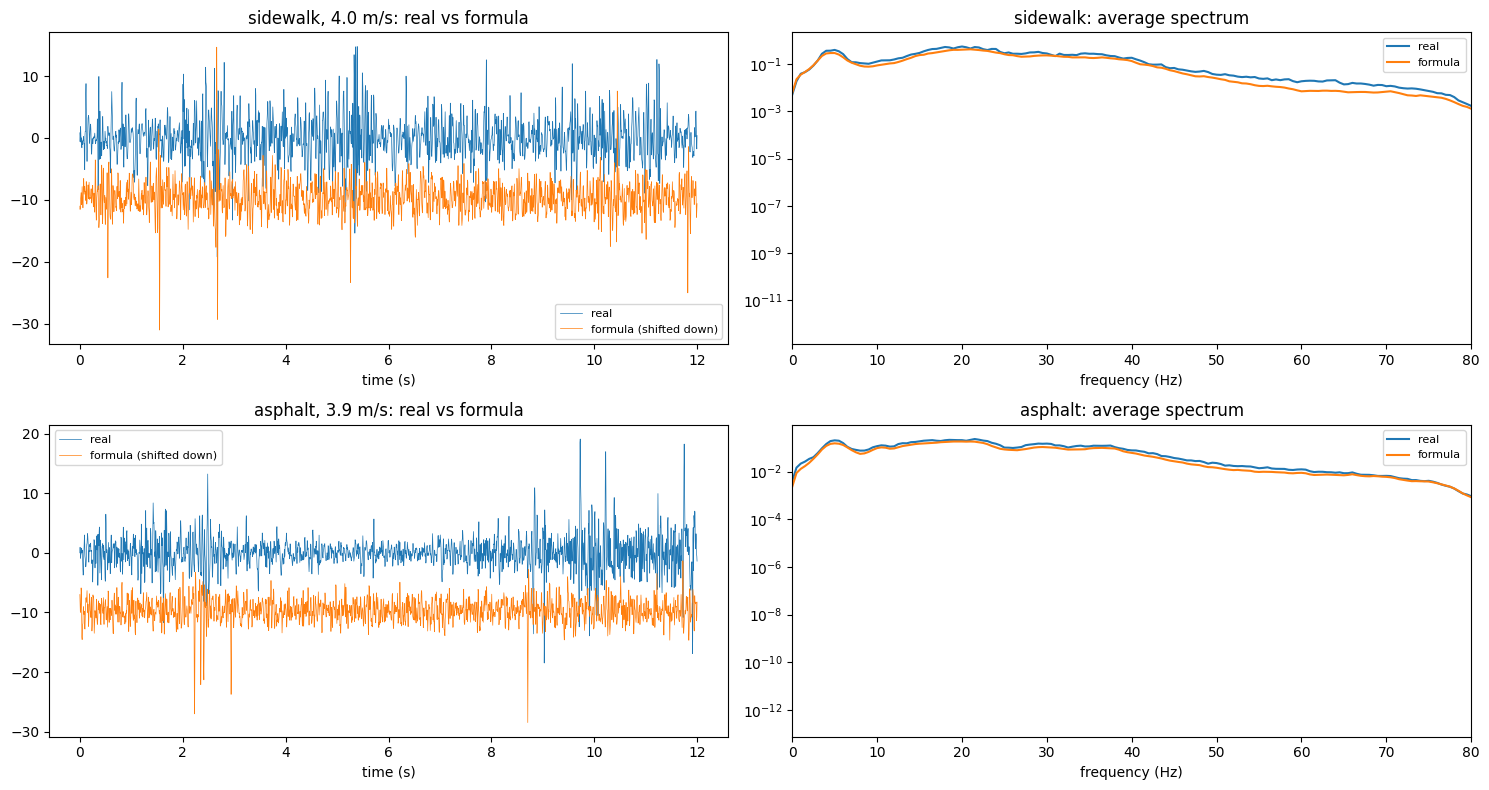

RMS formula / real: median 1.02, middle 50% of windows 0.73..1.31


In [13]:
# 13. Test of the formula: synthetic signal made from surface and speed only, compared with the real one

def synth(c, v, n = win_s * fs, rng = rng):
    m = model[c]
    freq = np.fft.rfftfreq(n, 1 / fs)
    amp = np.sqrt(np.interp(freq, m["shape_f"], m["shape"], left = 0, right = 0))
    x = np.fft.irfft(amp * np.exp(2j * np.pi * rng.random(len(freq))), n)
    x *= m["K_base"] * (v / v_ref) ** m["alpha_base"] / np.sqrt(np.mean(x ** 2))
    t = np.arange(n) / fs
    if m["wheel_K"] > 0:
        x += m["wheel_K"] * (v / v_ref) ** m["wheel_alpha"] * np.sin(2 * np.pi * v / C_wheel * t + rng.random() * 2 * np.pi)
    if len(m["hit_amps"]):
        h = len(m["template"]) // 2
        for p in rng.integers(h, n - h, rng.poisson(m["hits_per_m"] * v * n / fs)):
            x[p - h:p + h + 1] += rng.choice(m["hit_amps"]) * rng.choice([-1, 1]) * m["template"]
    return x

def numbers(x):
    fx, Px = welch(x, fs = fs, nperseg = 2 * fs)
    row = {"rms_vert": np.sqrt(np.mean(x ** 2))}
    for name, (lo, hi) in bands.items():
        row[f"rms_{name}"] = np.sqrt(Px[(fx >= lo) & (fx < hi)].sum() * (fx[1] - fx[0]))
    row["hits_per_s"] = len(find_peaks(np.abs(x), height = hit_theta, distance = int(0.1 * fs))[0]) / win_s
    return row

syn = pd.DataFrame([numbers(synth(c, v)) for c, v in zip(feat["label"], feat["speed_mps"])])
cols = ["rms_vert"] + [f"rms_{b}" for b in bands] + ["hits_per_s"]
feat["speed_group"] = pd.cut(feat["speed_mps"], speed_edges).astype(str)
comp = pd.concat([feat[["label", "speed_group"] + cols].assign(source = "real"),
                  syn[cols].assign(label = feat["label"].to_numpy(), speed_group = feat["speed_group"].to_numpy(), source = "formula")])
table = comp.groupby(["label", "speed_group", "source"])[cols].median().unstack("source").round(2)
display(table)

fig, axes = plt.subplots(2, 2, figsize = (15, 8))
for row, c in enumerate(classes):
    i = int(np.argmin(np.abs(feat["speed_mps"] - v_ref) + 100 * (feat["label"] != c)))
    v = feat.at[i, "speed_mps"]
    xs = synth(c, v)
    t = np.arange(win_s * fs) / fs
    axes[row, 0].plot(t, a_vert[i], linewidth = 0.5, label = "real")
    axes[row, 0].plot(t, xs - 4 * feat["rms_vert"].median(), linewidth = 0.5, label = "formula (shifted down)")
    axes[row, 0].set_title(f"{c}, {v:.1f} m/s: real vs formula")
    axes[row, 0].set_xlabel("time (s)")
    sel = (feat["label"] == c).to_numpy()
    syn_P = np.array([welch(synth(c, vv), fs = fs, nperseg = 2 * fs)[1] for vv in feat.loc[sel, "speed_mps"]])
    axes[row, 1].semilogy(f, P[sel].mean(axis = 0), label = "real")
    axes[row, 1].semilogy(f, syn_P.mean(axis = 0), label = "formula")
    axes[row, 1].set_xlim(0, 80)
    axes[row, 1].set_title(f"{c}: average spectrum")
    axes[row, 1].set_xlabel("frequency (Hz)")
    for ax in axes[row]:
        ax.legend(fontsize = 8)
plt.tight_layout()
plt.savefig(out_dir / "formula_vs_real.png", dpi = 150)
plt.show()

err = (np.log(syn["rms_vert"].to_numpy()) - np.log(feat["rms_vert"].to_numpy()))
print(f"RMS formula / real: median {np.exp(np.median(err)):.2f}, middle 50% of windows {np.exp(np.percentile(err, 25)):.2f}..{np.exp(np.percentile(err, 75)):.2f}")

In [14]:
# 14. Save the formula (vibration_formula.json)

formula = {"v_ref_mps": v_ref, "fs_hz": fs, "wheel_C_m": C_wheel if clear_wheel else None, "surfaces": {}}
for c in classes:
    m = model[c]
    keep_f = m["shape_f"] <= 80
    formula["surfaces"][c] = {
        "speed_range_mps": params["surfaces"][c]["speed_range_mps"],
        "base": {"K": float(m["K_base"]), "alpha": float(m["alpha_base"]), "R2": float(m["R2_base"]),
                 "shape_f_hz": m["shape_f"][keep_f].round(2).tolist(), "shape_share_per_hz": m["shape"][keep_f].tolist()},
        "wheel": {"K": float(m["wheel_K"]), "alpha": float(m["wheel_alpha"])},
        "hits": {"per_m": float(m["hits_per_m"]), "size_quantiles_mps2": np.percentile(m["hit_amps"], [10, 25, 50, 75, 90]).tolist() if len(m["hit_amps"]) else [],
                 "shape_200hz": m["template"].round(4).tolist()},
    }
with open(out_dir / "vibration_formula.json", "w") as fh:
    json.dump(formula, fh, indent = 1)
print("saved", out_dir / "vibration_formula.json")
for c, s in formula["surfaces"].items():
    print(f"{c:9s} a(t) = {s['base']['K']:.2f} * (v / {v_ref:g}) ^ {s['base']['alpha']:.2f} * noise(t)"
          + (f" + {s['wheel']['K']:.2f} * (v / {v_ref:g}) ^ {s['wheel']['alpha']:.2f} * sin(2 pi v t / {C_wheel:.2f})" if s['wheel']['K'] > 0 else "")
          + f" + hits ({s['hits']['per_m']:.2f} per metre)")

saved /content/drive/MyDrive/scooter_data/vibration_model/vibration_formula.json
sidewalk  a(t) = 2.12 * (v / 4) ^ 0.54 * noise(t) + 0.21 * (v / 4) ^ 0.28 * sin(2 pi v t / 0.69) + hits (0.33 per metre)
asphalt   a(t) = 1.67 * (v / 4) ^ 0.32 * noise(t) + 0.21 * (v / 4) ^ 0.49 * sin(2 pi v t / 0.69) + hits (0.08 per metre)


In [15]:
# 15. File for Unity (vibration_formula_unity.json): one alpha for both surfaces

lv = np.log(feat["speed_mps"] / v_ref).to_numpy()
A = np.column_stack([(feat["label"] == c).astype(float).to_numpy() for c in classes] + [lv])
coef, *_ = np.linalg.lstsq(A, np.log(feat["rms_base"].to_numpy()), rcond = None)
alpha_shared = float(coef[-1])

unity = {"vRef": v_ref, "alpha": alpha_shared, "wheelC": float(C_wheel) if clear_wheel else 0.0,
         "hitShapeFs": fs, "surfaces": []}
for k, c in enumerate(classes):
    m = model[c]
    keep_f = (m["shape_f"] > 0) & (m["shape_f"] <= 80)
    unity["surfaces"].append({
        "name": c,
        "K": float(np.exp(coef[k])),
        "shapeF": m["shape_f"][keep_f].round(3).tolist(),
        "shapeS": m["shape"][keep_f].tolist(),
        "wheelK": float(m["wheel_K"]),
        "wheelAlpha": float(m["wheel_alpha"]),
        "hitsPerM": float(m["hits_per_m"]),
        "hitSizes": np.percentile(m["hit_amps"], [5, 25, 50, 75, 95]).round(3).tolist() if len(m["hit_amps"]) else [0, 0, 0, 0, 0],
        "hitShape": m["template"].round(4).tolist(),
        "speedMin": params["surfaces"][c]["speed_range_mps"][0],
        "speedMax": params["surfaces"][c]["speed_range_mps"][1],
    })
with open(out_dir / "vibration_formula_unity.json", "w") as fh:
    json.dump(unity, fh)

print("saved", out_dir / "vibration_formula_unity.json")
print(f"alpha (both surfaces) = {alpha_shared:.2f}")
for s in unity["surfaces"]:
    print(f"   {s['name']:9s} base = {s['K']:.2f} * (v / {v_ref:g}) ^ {alpha_shared:.2f}, wheel {s['wheelK']:.2f}, "
          f"hits {s['hitsPerM']:.2f} per metre, sizes {s['hitSizes']}, data speed {s['speedMin']:.1f}-{s['speedMax']:.1f} m/s")

saved /content/drive/MyDrive/scooter_data/vibration_model/vibration_formula_unity.json
alpha (both surfaces) = 0.43
   sidewalk  base = 2.12 * (v / 4) ^ 0.43, wheel 0.21, hits 0.33 per metre, sizes [10.076, 11.471, 13.926, 18.134, 26.703], data speed 2.5-5.8 m/s
   asphalt   base = 1.62 * (v / 4) ^ 0.43, wheel 0.21, hits 0.08 per metre, sizes [9.79, 10.782, 12.367, 15.58, 26.438], data speed 3.3-7.6 m/s
